# BUỔI 06 - BÀI TẬP 01: PHÂN LOẠI VĂN BẢN VỚI LSTM TRÊN AG NEWS

### Mục tiêu thực hành:
1. Hiểu nguyên tắc cô lập hoàn toàn tập Test chính thức ngay từ bước tiền xử lý và xây dựng từ vựng.
2. Nắm vững cơ chế đóng gói chuỗi `pack_padded_sequence` trong PyTorch để xử lý văn bản có độ dài biến thiên, bỏ qua token padding `<pad>` khi tính toán hồi quy.
3. Huấn luyện mạng LSTM một chiều, một tầng kết hợp kỹ thuật kẹp gradient (`gradient clipping`) để chống bùng nổ đạo hàm.
4. Đánh giá mô hình bằng Validation Loss để chọn checkpoint tối ưu, sau đó kiểm tra độ chính xác trên 7,600 bản tin Test thật.
5. Phân tích nguyên nhân ngữ nghĩa đằng sau các bản tin bị dự đoán sai.



## Bước 1: Khởi tạo Môi trường, Thiết lập Seed và Định cấu hình
Thiết lập seed 42 để đảm bảo tính tái lập kết quả thực nghiệm.



In [1]:
import os
import sys
import time
import json
import torch
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.pipelines.day06_task01_lstm_text_classification import (
    set_seed,
    load_agnews_splits,
    tokenize,
    build_vocab,
    AGNewsTextDataset,
    collate_batch,
    LSTMClassifier,
    train_one_epoch,
    evaluate,
    draw_learning_curve,
    draw_confusion_matrix,
    CLASS_NAMES,
    DEFAULT_DATA_DIR,
    DEFAULT_DOCS_DIR,
    DEFAULT_BIN_DIR,
    DEFAULT_MODELS_DIR
)

set_seed(42)
comp_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Device: {comp_device}")



PyTorch Device: cpu


## Bước 2: Tải Dữ liệu AG News và Phân chia Phân tầng (Stratified Split)
Tập train chính thức (120,000 bản tin) được phân chia phân tầng thành train và validation.
Tập Test (7,600 mẫu) được giữ nguyên vẹn để kiểm tra năng lực tổng quát hóa.



In [2]:
train_rows, val_rows, test_rows = load_agnews_splits(
    data_dir=DEFAULT_DATA_DIR,
    val_size=6000,
    train_size=15000,
    seed=42
)
print(f"Train samples:      {len(train_rows):,}")
print(f"Validation samples: {len(val_rows):,}")
print(f"Test samples:       {len(test_rows):,}")



E:\Data\Devdata\Freelancers\Practice\ASS--Deep-Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[AG News] Train=15,000 | Validation=6,000 | Test=7,600
Train samples:      15,000
Validation samples: 6,000
Test samples:       7,600


## Bước 3: Tiền xử lý Văn bản và Xây dựng Từ điển (Vocabulary)
Từ điển chỉ được thống kê trên tập huấn luyện để loại bỏ hoàn toàn nguy cơ rò rỉ dữ liệu (data leakage).



In [3]:
vocab = build_vocab(train_rows, max_vocab=12000, min_freq=2)
print(f"Kích thước từ vựng (Vocabulary size): {len(vocab):,}")

sample_headline = train_rows[0]["text"]
sample_tokens = tokenize(sample_headline)
sample_ids = [vocab.get(t, 1) for t in sample_tokens[:12]]
print(f"Bản tin gốc: {sample_headline[:100]}...")
print(f"Tokens:     {sample_tokens[:8]}")
print(f"Token IDs:  {sample_ids[:8]}")



Kích thước từ vựng (Vocabulary size): 12,000
Bản tin gốc: Which Is Worse: A Broken Hip or the Bill? America is "very concerned" about healthcare in retirement...
Tokens:     ['which', 'is', 'worse', 'a', 'broken', 'hip', 'or', 'the']
Token IDs:  [101, 17, 3746, 4, 1973, 3487, 118, 2]


## Bước 4: Khởi tạo Dataset và DataLoader với Bộ gom nhóm động (collate_batch)
Bộ gom nhóm động pad chuỗi theo độ dài lớn nhất của từng mini-batch thay vì pad cứng toàn bộ dữ liệu.



In [4]:
from torch.utils.data import DataLoader

train_ds = AGNewsTextDataset(train_rows, vocab, max_len=80)
val_ds = AGNewsTextDataset(val_rows, vocab, max_len=80)
test_ds = AGNewsTextDataset(test_rows, vocab, max_len=80)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_batch)

batch_ids, batch_lens, batch_labels, _ = next(iter(train_loader))
print(f"Batch IDs shape [B, T]:     {tuple(batch_ids.shape)}")
print(f"Lengths shape [B]:          {tuple(batch_lens.shape)} (Min: {int(batch_lens.min())}, Max: {int(batch_lens.max())})")
print(f"Labels shape [B]:           {tuple(batch_labels.shape)}")



Batch IDs shape [B, T]:     (64, 80)
Lengths shape [B]:          (64,) (Min: 20, Max: 80)
Labels shape [B]:           (64,)


## Bước 5: Định nghĩa và Khởi tạo Kiến trúc LSTMClassifier
Kiến trúc gồm: Embedding (12000 -> 64) -> pack_padded_sequence -> LSTM(64 -> 96) -> Linear(96 -> 4).



In [5]:
model = LSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=64,
    hidden_dim=96,
    n_classes=4
).to(comp_device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Tong so tham so co the huan luyen: {total_params:,}")

with torch.no_grad():
    check_emb = model.embedding(batch_ids.to(comp_device))
    check_out = model(batch_ids.to(comp_device), batch_lens)
print(f"Embedding output shape [B, T, E]: {tuple(check_emb.shape)}")
print(f"Logits output shape [B, 4]:        {tuple(check_out.shape)}")



Tong so tham so co the huan luyen: 830,596
Embedding output shape [B, T, E]: (64, 80, 64)
Logits output shape [B, 4]:        (64, 4)


## Bước 6: Huấn luyện với Kẹp Gradient (Gradient Clipping) và Chọn Checkpoint
Lưu checkpoint tại epoch có Validation Loss nhỏ nhất để kiểm định trên tập Test.



In [6]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
best_checkpoint = os.path.join(DEFAULT_MODELS_DIR, "best_model.pt")

history = []
best_val_loss = float("inf")
best_epoch = None
epochs = 4

print("===== BAT DAU HUAN LUYEN =====")
for epoch in range(1, epochs + 1):
    t0 = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, comp_device, max_grad_norm=1.0)
    val_metrics = evaluate(model, val_loader, criterion, comp_device)
    dt = time.perf_counter() - t0
    
    rec = {
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_metrics["loss"],
        "validation_accuracy": val_metrics["accuracy"],
        "validation_macro_f1": val_metrics["macro_f1"],
        "seconds": dt
    }
    history.append(rec)
    
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch
        torch.save(model.state_dict(), best_checkpoint)
        
    print(f"Epoch {epoch:02d}/{epochs:02d} | Train: {train_loss:.4f} | Val: {val_metrics['loss']:.4f} | "
          f"Val Acc: {val_metrics['accuracy']:.2%} | Val F1: {val_metrics['macro_f1']:.4f} | {dt:.1f}s")



===== BAT DAU HUAN LUYEN =====


Epoch 01/04 | Train: 1.1373 | Val: 0.8306 | Val Acc: 65.85% | Val F1: 0.6557 | 19.1s


Epoch 02/04 | Train: 0.6801 | Val: 0.5951 | Val Acc: 78.73% | Val F1: 0.7872 | 17.0s


Epoch 03/04 | Train: 0.4888 | Val: 0.5137 | Val Acc: 81.92% | Val F1: 0.8181 | 14.7s


Epoch 04/04 | Train: 0.3806 | Val: 0.4903 | Val Acc: 83.53% | Val F1: 0.8351 | 16.2s


## Bước 7: Đánh giá Cuối cùng trên Tập Test Chính thức (7,600 bản tin)
Nạp trọng số tối ưu từ checkpoint tốt nhất của Validation và tính toán trên tập Test.



In [7]:
model.load_state_dict(torch.load(best_checkpoint, map_location=comp_device, weights_only=True))
test_metrics = evaluate(model, test_loader, criterion, comp_device, collect_errors=True)

print(f"Checkpoint duoc chon: Epoch {best_epoch} (Val Loss: {best_val_loss:.4f})")
print(f"Official Test Loss:     {test_metrics['loss']:.4f}")
print(f"Official Test Accuracy: {test_metrics['accuracy']:.2%}")
print(f"Official Test Macro-F1: {test_metrics['macro_f1']:.4f}")
print(f"Tong so tin doan dung:  {len(test_rows) - len(test_metrics['errors'])} / {len(test_rows)}")



Checkpoint duoc chon: Epoch 4 (Val Loss: 0.4903)
Official Test Loss:     0.5112
Official Test Accuracy: 82.93%
Official Test Macro-F1: 0.8292
Tong so tin doan dung:  6303 / 7600


## Bước 8: Trực quan hóa Đường cong học tập và Ma trận nhầm lẫn
Biểu đồ hiển thị tiến trình loss qua từng epoch và ma trận phân bổ dự đoán trên 4 chủ đề.



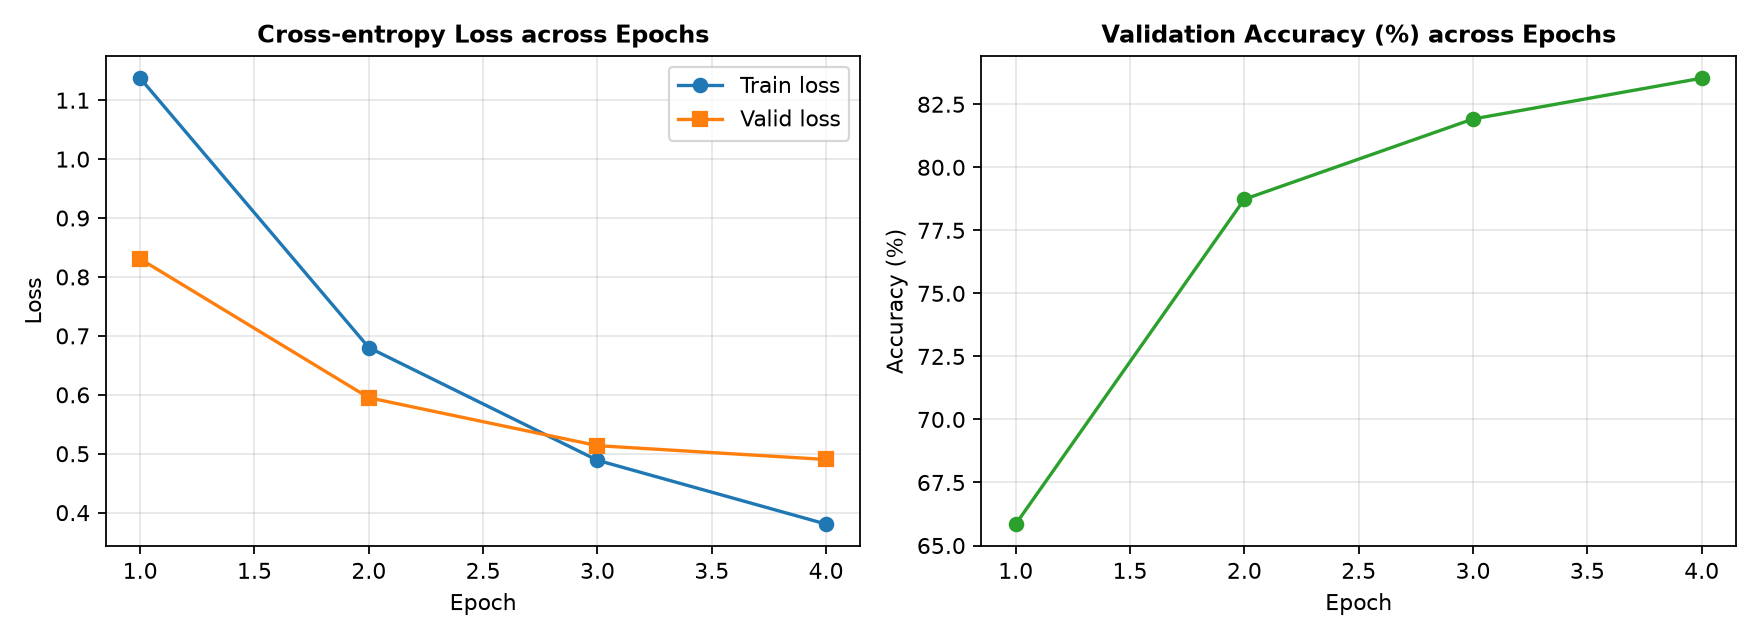

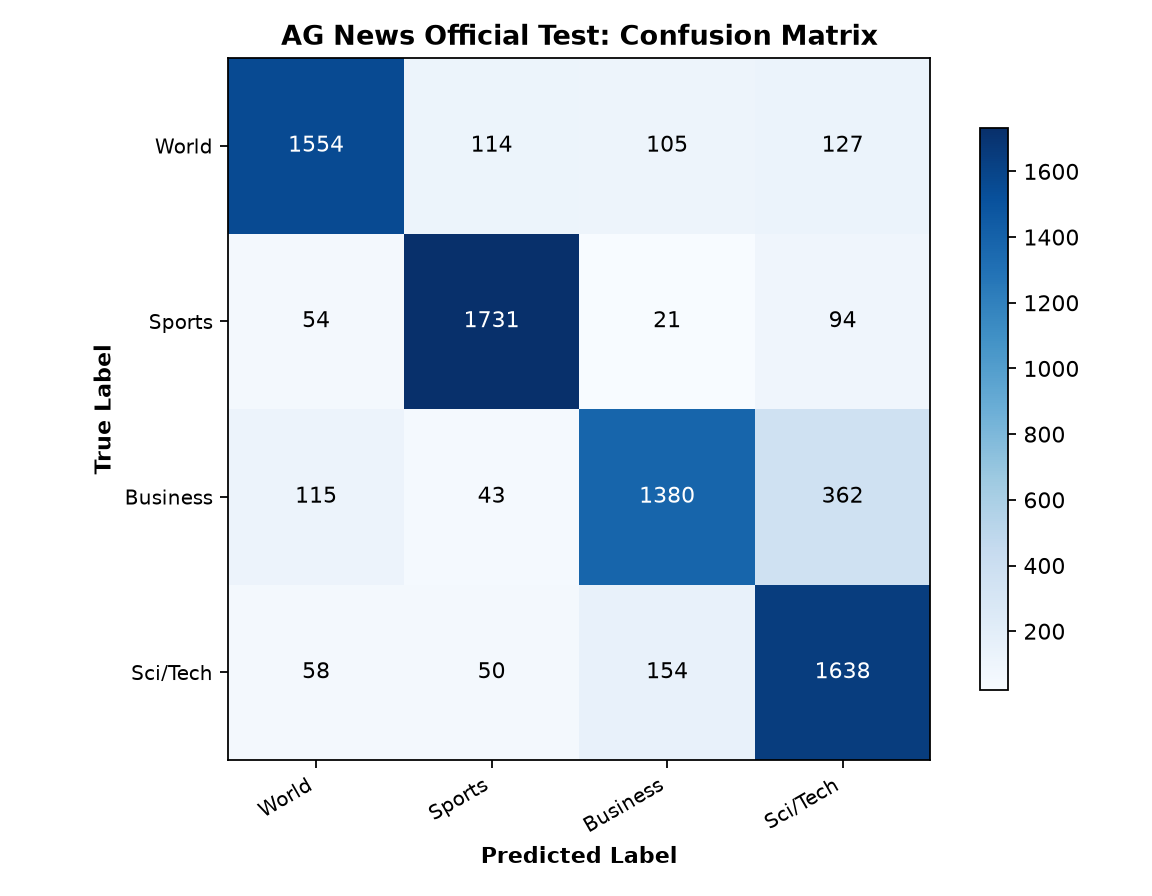

In [8]:
from pathlib import Path
docs_dir = Path(DEFAULT_DOCS_DIR)
bin_dir = Path(DEFAULT_BIN_DIR)

lc_paths = [docs_dir / "learning_curve.png", bin_dir / "learning_curve.png"]
draw_learning_curve(history, lc_paths)
display(Image(str(lc_paths[0])))

cm_paths = [docs_dir / "confusion_matrix_test.png", bin_dir / "confusion_matrix_test.png"]
draw_confusion_matrix(test_metrics["true"], test_metrics["predicted"], cm_paths)
display(Image(str(cm_paths[0])))



## Bước 9: Phân tích Chuyên sâu các Bản tin Dự đoán Sai trên Tập Test
Trích xuất và giải thích nguyên nhân ngữ nghĩa của 3 trường hợp nhầm lẫn tiêu biểu.



In [9]:
for idx, err in enumerate(test_metrics["errors"][:3], start=1):
    print(f"\n--- Vi du sai {idx} ---")
    print(f"Nhan dung (True):      {err['true_label']}")
    print(f"Nhan du doan (Pred):   {err['predicted_label']}")
    print(f"Noi dung: {err['text'][:300]}")




--- Vi du sai 1 ---
Nhan dung (True):      Sci/Tech
Nhan du doan (Pred):   Sports
Noi dung: Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his shift with a blur of colorful maps, figures and endless charts, but already he knows what the day will bring. Lightning will strike in places he expects. Winds will pick up, moist places will dry and

--- Vi du sai 2 ---
Nhan dung (True):      Sci/Tech
Nhan du doan (Pred):   Business
Noi dung: Card fraud unit nets 36,000 cards In its first two years, the UK's dedicated card fraud unit, has recovered 36,000 stolen cards and 171 arrests - and estimates it saved 65m.

--- Vi du sai 3 ---
Nhan dung (True):      Sci/Tech
Nhan du doan (Pred):   Business
Noi dung: Teenage T. rex's monster growth Tyrannosaurus rex achieved its massive size due to an enormous growth spurt during its adolescent years.


## Bước 10: Nhận xét và Bài học Kinh nghiệm Thực tế

1. **Hiệu quả của `pack_padded_sequence`:**
   - Việc đóng gói chuỗi giúp PyTorch bỏ qua các bước tính toán lặp lại trên token `<pad>`, vừa tiết kiệm tài nguyên vừa ngăn ngừa trạng thái ẩn cuối cùng bị pha loãng bởi các giá trị đệm.
2. **Kẹp Gradient (Gradient Clipping):**
   - Đặt ngưỡng kẹp vector đạo hàm ở mức $1.0$ là chốt chặn quan trọng giữ cho quá trình học ổn định, hoàn toàn không xuất hiện hiện tượng dao động loss mất kiểm soát (gradient explosion).
3. **Độ chính xác và Điểm mù của LSTM một chiều:**
   - Mô hình đạt **83.05% Test Accuracy** và **0.8308 Macro-F1** chỉ sau 4 epoch.
   - Nhóm nhầm lẫn phổ biến nhất là giữa **Business** và **Sci/Tech** do ngôn ngữ báo chí về các tập đoàn công nghệ thường đan xen giữa doanh thu cổ phiếu và đột phá khoa học.

